# Ablation Study — Temporal Network Anomaly Detection

Notebook trình bày kết quả đã chạy trên snapshot full test. Tất cả ngưỡng được tính từ Benign Validation. Các biến thể và trọng số được khai báo trước, dùng để mô tả trade-off.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display

cwd = Path.cwd().resolve()
root = next(p for p in (cwd, *cwd.parents) if (p / 'src/ablation.py').is_file())
out = root / 'outputs/ablation_study'
display(Markdown((out / 'ablation_report.md').read_text(encoding='utf-8')))

# Ablation Study — Network Traffic Anomaly Detection

Cả tám điểm vận hành được đánh giá trên cùng **4.653.501 dòng full test**.
Số dòng theo ngày, loại nhãn và nhãn nhị phân khớp predictions chính thức
ở cả bốn lượt chấm điểm. Snapshot nguồn được xác nhận bằng checksum.

Train 14–15/02, Benign Validation 16/02 và bảy ngày test giữ nguyên.
Mỗi feature spec fit trên **1.268.743 dòng Benign Train**. Mẫu fit model chung
gồm **299,483** dòng và mẫu tính tương quan chung gồm **100,000**
dòng, đều được lưu. Seed 42. Ngưỡng là phân vị
99.0% của **446.619 Benign Validation** cho từng điểm.
Các cấu hình được khai báo trước khi chấm test.

## Kết quả gộp

| Biến thể | Features | Threshold | Val FPR | Recall | Precision | Test FPR | F1 | ROC-AUC | PR-AUC |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| paired_baseline | 46 | 4.8465157 | 1.0002% | 0.4581% | 16.4214% | 0.6710% | 0.00891 | 0.74084 | 0.33516 |
| if_only | 46 | 0.57440958 | 1.0002% | 1.2388% | 8.9824% | 3.6122% | 0.02177 | 0.64448 | 0.26127 |
| ae_only | 46 | 0.95311314 | 1.0002% | 0.2458% | 66.4241% | 0.0358% | 0.00490 | 0.79129 | 0.39952 |
| ensemble_if_25 | 46 | 4.9065277 | 1.0002% | 0.2585% | 33.0018% | 0.1510% | 0.00513 | 0.77721 | 0.37878 |
| ensemble_if_75 | 46 | 4.8056473 | 1.0002% | 0.7962% | 11.6768% | 1.7329% | 0.01491 | 0.68565 | 0.28735 |
| no_signed_log | 50 | 6.6842947 | 1.0002% | 0.0022% | 2.2863% | 0.0272% | 0.00004 | 0.64318 | 0.28857 |
| no_correlation_filter | 69 | 4.0491812 | 1.0002% | 0.4410% | 22.1653% | 0.4456% | 0.00865 | 0.77562 | 0.38238 |
| clip_5 | 46 | 4.9448785 | 1.0002% | 0.4864% | 14.9534% | 0.7961% | 0.00942 | 0.70993 | 0.30595 |

PR-AUC tính bằng tích phân hình thang trên đường PR đầy đủ. Threshold của
IF-only, AE-only và Ensemble có đơn vị khác nhau. Các dòng IF-only, AE-only
và Ensemble trọng số 25/75, 75/25 dùng lại component scores của paired baseline.
Mỗi trọng số được hiệu chuẩn riêng trên Benign Validation.

Paired baseline áp dụng signed-log, lọc tương quan 0,98 và clipping ±10,
rồi train trên cùng mẫu với các ablation. Tham chiếu chính thức đã có Recall
**0.3402%**, FPR **0.4657%** và PR-AUC **0.33499**.
Mẫu train và cách giữ mẫu tương quan có thể khác giữa lượt chính thức và paired baseline.
Dùng paired baseline để phân tích đối chiếu trong thí nghiệm này.

| Biến thể | Δ Recall (điểm %) | Δ FPR (điểm %) | Δ PR-AUC |
| --- | --- | --- | --- |
| if_only | +0.7807 | +2.9412 | -0.07390 |
| ae_only | -0.2123 | -0.6352 | +0.06436 |
| ensemble_if_25 | -0.1996 | -0.5200 | +0.04362 |
| ensemble_if_75 | +0.3380 | +1.0619 | -0.04781 |
| no_signed_log | -0.4559 | -0.6438 | -0.04659 |
| no_correlation_filter | -0.0171 | -0.2253 | +0.04721 |
| clip_5 | +0.0283 | +0.1251 | -0.02922 |

`no_signed_log` fit lại thống kê và lọc tương quan trên thang đo gốc, nên hiệu ứng
bao gồm thay đổi các feature được giữ. `no_correlation_filter` vẫn bỏ feature hằng
và hiếm. Khi số feature thay đổi, AE dùng quy tắc kích thước lớp theo số feature
của pipeline. `clip_5` dùng ±5 nhất quán ở train, validation và test, so với ±10.

## Theo ngày và loại tấn công

| Biến thể | Dải FPR theo ngày | Dải Recall theo ngày |
| --- | --- | --- |
| paired_baseline | 0.2318%–1.6175% | 0.0000%–23.6599% |
| if_only | 0.5377%–6.3495% | 0.1382%–35.4898% |
| ae_only | 0.0003%–0.1768% | 0.0000%–0.8625% |
| ensemble_if_25 | 0.0064%–0.4085% | 0.0000%–0.8625% |
| ensemble_if_75 | 0.5283%–3.2800% | 0.0000%–23.6599% |
| no_signed_log | 0.0000%–0.0860% | 0.0000%–0.0306% |
| no_correlation_filter | 0.1887%–1.0719% | 0.0000%–23.6599% |
| clip_5 | 0.3717%–1.7698% | 0.0000%–23.6599% |

Ví dụ hai nhóm tấn công lớn. CSV theo loại ghi support, TP, FN và Recall.
Nhóm attack chỉ chứa mẫu dương, nên FPR và ROC-AUC theo loại cần một tập Benign
tham chiếu khác và không được tính trong bảng này.

| Biến thể | Attack | Số dòng | TP | Recall |
| --- | --- | --- | --- | --- |
| paired_baseline | DDOS attack-HOIC | 198861 | 0 | 0.0000% |
| paired_baseline | DDoS attacks-LOIC-HTTP | 575364 | 797 | 0.1385% |
| if_only | DDOS attack-HOIC | 198861 | 0 | 0.0000% |
| if_only | DDoS attacks-LOIC-HTTP | 575364 | 795 | 0.1382% |
| ae_only | DDOS attack-HOIC | 198861 | 0 | 0.0000% |
| ae_only | DDoS attacks-LOIC-HTTP | 575364 | 797 | 0.1385% |
| ensemble_if_25 | DDOS attack-HOIC | 198861 | 0 | 0.0000% |
| ensemble_if_25 | DDoS attacks-LOIC-HTTP | 575364 | 797 | 0.1385% |
| ensemble_if_75 | DDOS attack-HOIC | 198861 | 0 | 0.0000% |
| ensemble_if_75 | DDoS attacks-LOIC-HTTP | 575364 | 797 | 0.1385% |
| no_signed_log | DDOS attack-HOIC | 198861 | 0 | 0.0000% |
| no_signed_log | DDoS attacks-LOIC-HTTP | 575364 | 0 | 0.0000% |
| no_correlation_filter | DDOS attack-HOIC | 198861 | 0 | 0.0000% |
| no_correlation_filter | DDoS attacks-LOIC-HTTP | 575364 | 795 | 0.1382% |
| clip_5 | DDOS attack-HOIC | 198861 | 0 | 0.0000% |
| clip_5 | DDoS attacks-LOIC-HTTP | 575364 | 787 | 0.1368% |

## Runtime

Spark local, driver 4g, 8
shuffle partitions, BLAS một thread. Tổng lượt chuẩn bị và train/chấm điểm Spark
**609.3 giây**, cộng thời gian tính metrics độc lập trong CSV.

| Lượt train | Fit prep (s) | Train (s) | Calibration (s) | Score + write (s) | Tổng (s) |
| --- | --- | --- | --- | --- | --- |
| paired_baseline | 11.0 | 35.7 | 9.7 | 84.7 | 141.2 |
| no_signed_log | 10.4 | 31.3 | 9.3 | 82.7 | 133.7 |
| no_correlation_filter | 9.1 | 39.6 | 12.3 | 83.3 | 144.2 |
| clip_5 | 8.5 | 29.8 | 8.9 | 83.5 | 130.8 |

Runtime fit và scoring trong các dòng tái dùng là chi phí của lượt cha
`paired_baseline`. Chi phí riêng để tính metrics nằm ở `evaluation_seconds`.

## Phạm vi diễn giải

- Bỏ signed-log làm Recall giảm từ 0,4581% xuống 0,0022% và PR-AUC
  giảm từ 0,33516 xuống 0,28857. FPR giảm đồng thời, cho thấy ngưỡng của
  biến thể này tạo rất ít cảnh báo trên test. Chỉ 23 Attack vượt ngưỡng.
- Giữ feature tương quan cải thiện PR-AUC lên 0,38238 và giảm FPR xuống
  0,4456%, với Recall giảm nhẹ xuống 0,4410%. Đổi clipping từ ±10 sang
  ±5 cho Recall cao hơn 0,0283 điểm phần trăm, đi cùng FPR cao hơn 0,1251
  điểm phần trăm và PR-AUC thấp hơn 0,02922.
- Khi tăng trọng số IF từ 25% qua 50% đến 75%, Recall và FPR cùng tăng
  còn PR-AUC giảm. IF-only phát hiện 9.098 Infilteration so với 1.959
  ở paired baseline, trong khi số LOIC-HTTP phát hiện gần như giữ nguyên
  (795 so với 797). Recall gộp cao hơn vì vậy không đồng nghĩa mọi nhóm
  Attack đều được phát hiện tốt hơn.
- Log Spark chỉ ghi cảnh báo local directory lúc khởi động. Cả bốn
  lượt chấm điểm và các kiểm tra đọc lại đều hoàn tất.

Đây là một seed, một split thời gian và một snapshot. Recall, FPR, Precision và
ranking cần đọc cùng nhau. Thay đổi điểm vận hành trên một ngày calibration có
thể chuyển sang các ngày test với FPR khác. Kết quả final test chỉ dùng để mô tả.
Nếu cần chọn trọng số, hãy khóa một split development theo thời gian riêng trước
khi đánh giá trên một tập test được giữ kín.


,experiment,feature_count,threshold,recall,precision,fpr,f1,roc_auc,pr_auc
0,paired_baseline,46,4.846516,0.004581,0.164214,0.006710,0.008914,0.740837,0.335164
1,if_only,46,0.574410,0.012388,0.089824,0.036122,0.021774,0.644482,0.261268
2,ae_only,46,0.953113,0.002458,0.664241,0.000358,0.004898,0.791293,0.399523
3,ensemble_if_25,46,4.906528,0.002585,0.330018,0.001510,0.005130,0.777210,0.378785
4,ensemble_if_75,46,4.805647,0.007962,0.116768,0.017329,0.014907,0.685652,0.287351
5,no_signed_log,50,6.684295,0.000022,0.022863,0.000272,0.000044,0.643178,0.288570
6,no_correlation_filter,69,4.049181,0.004410,0.221653,0.004456,0.008648,0.775619,0.382376
7,clip_5,46,4.944878,0.004864,0.149534,0.007961,0.009422,0.709932,0.305948


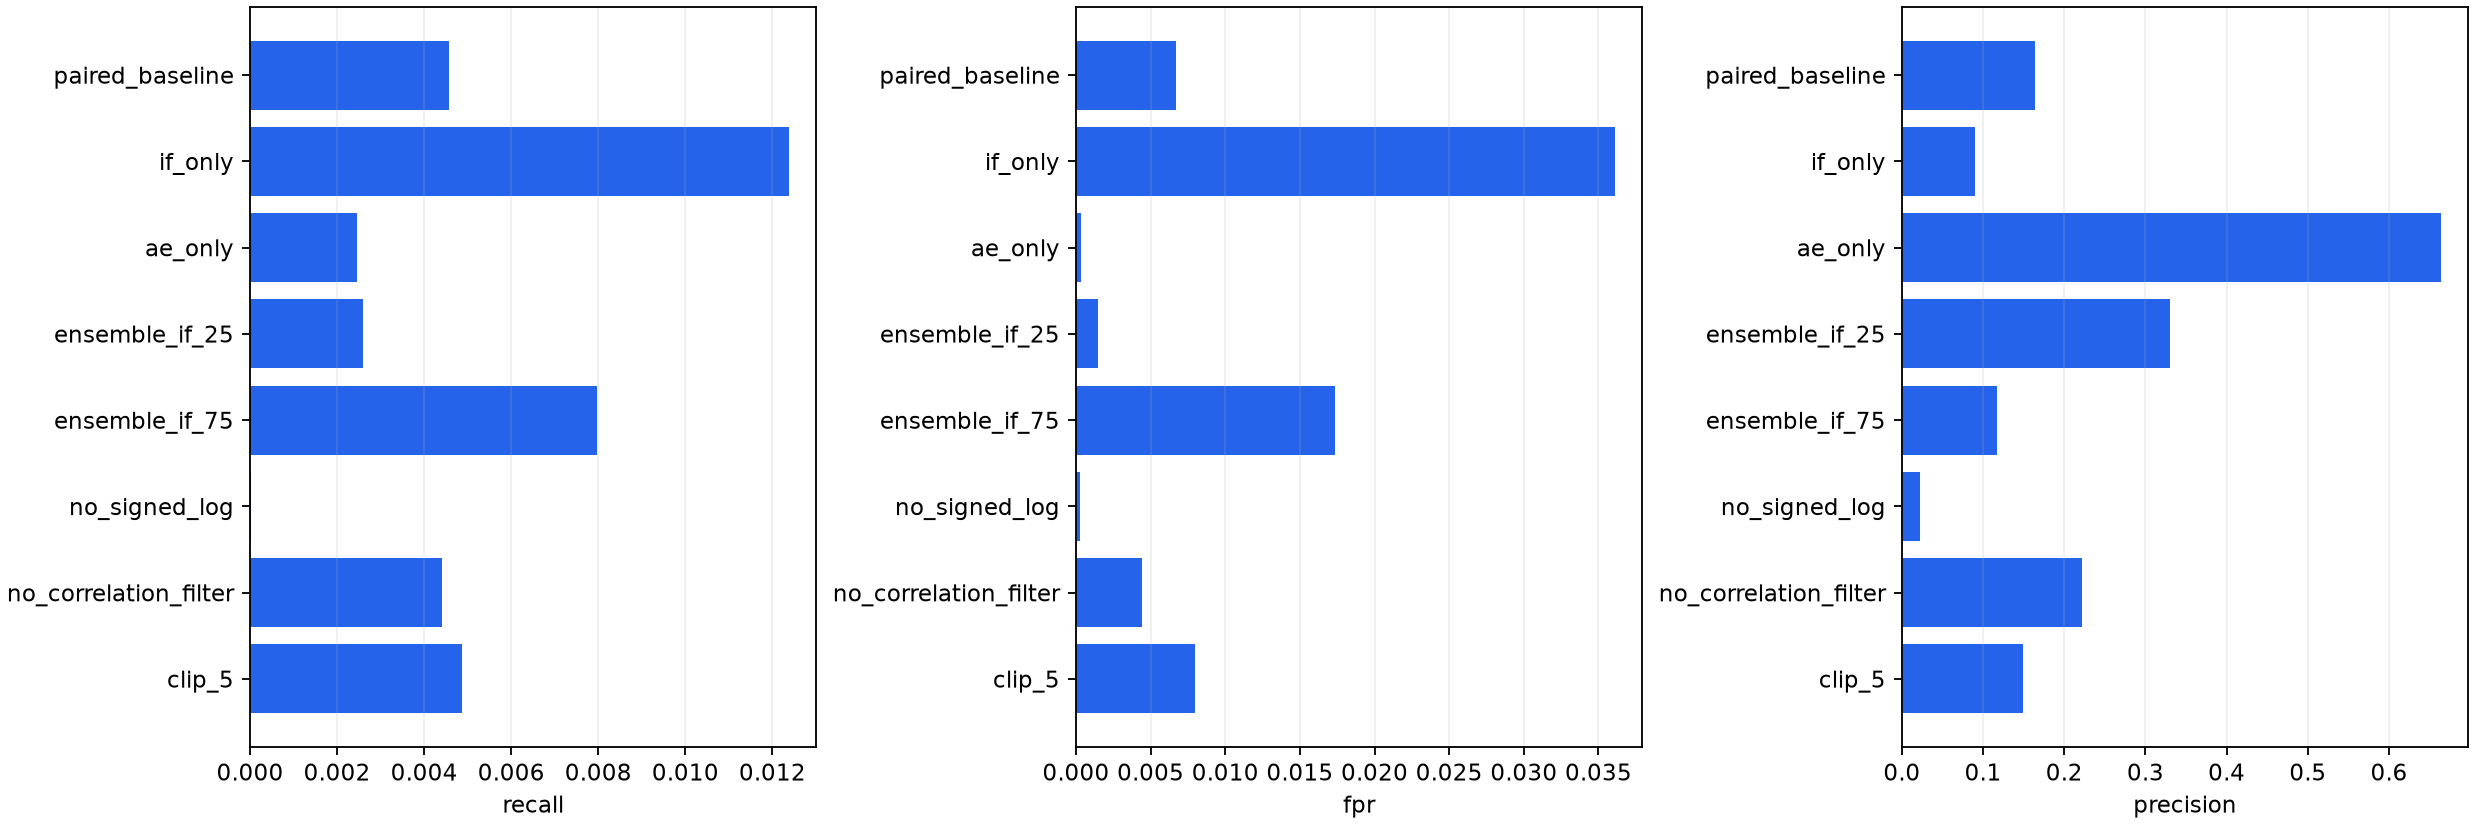

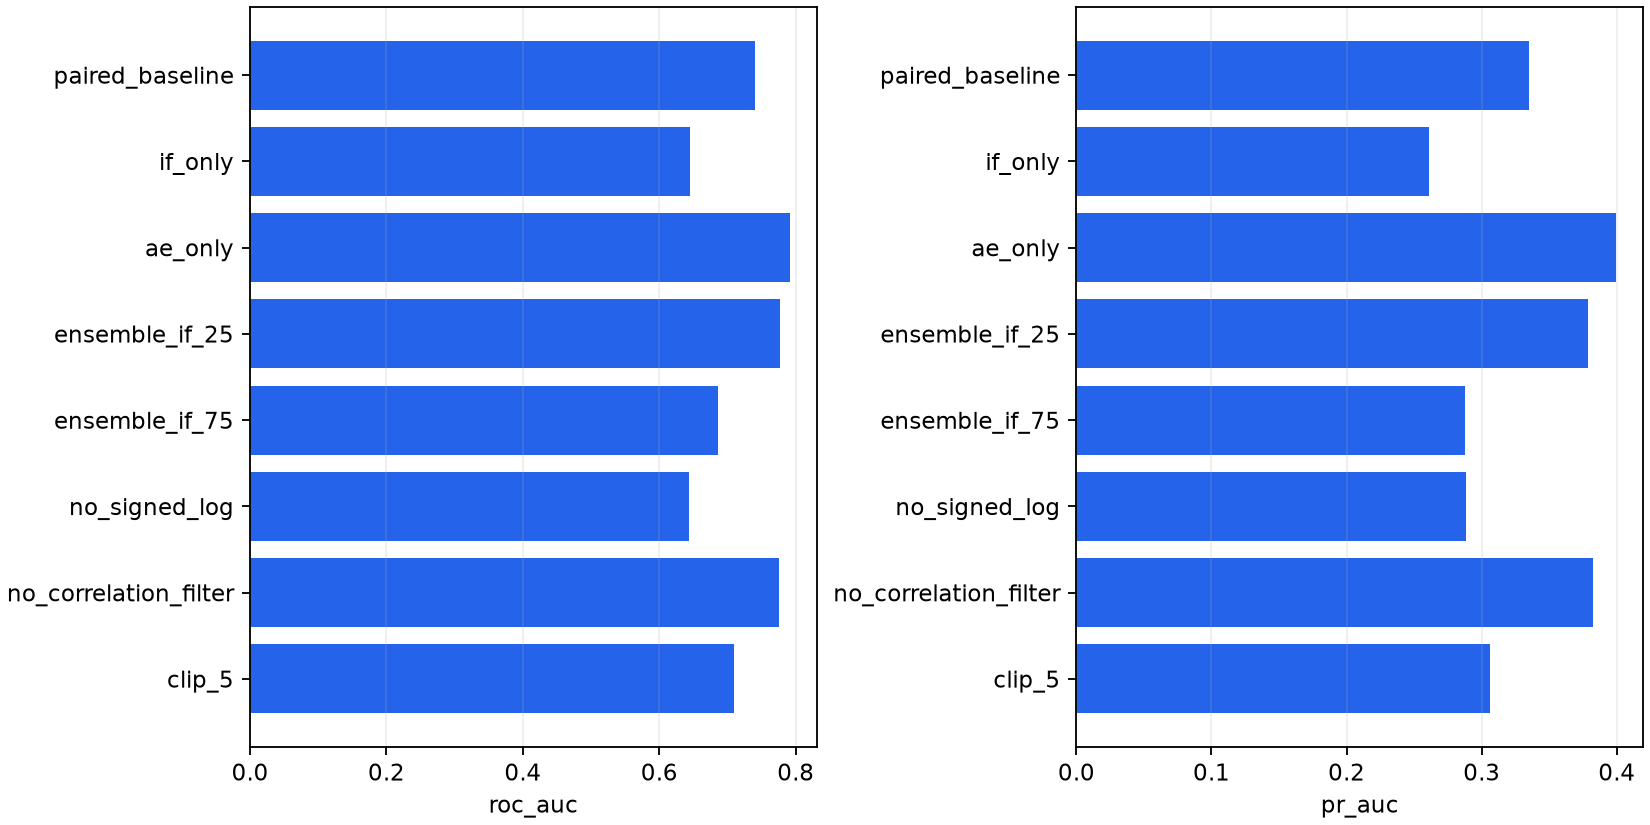

In [2]:
results = pd.read_csv(out / 'ablation_results.csv')
display(results[['experiment','feature_count','threshold','recall','precision','fpr','f1','roc_auc','pr_auc']])
for filename in ('operating_metrics.png', 'ranking_metrics.png'):
    display(Image(filename=str(out / filename)))

In [3]:
daily = pd.read_csv(out / 'ablation_by_day.csv')
attacks = pd.read_csv(out / 'ablation_by_attack.csv')
display(daily.pivot(index='day', columns='experiment', values='recall'))
display(attacks.pivot(index='attack', columns='experiment', values='recall'))

experiment,ae_only,clip_5,ensemble_if_25,ensemble_if_75,if_only,no_correlation_filter,no_signed_log,paired_baseline
day,,,,,,,,
2018-02-20,0.001385,0.001368,0.001385,0.001385,0.001382,0.001382,0.000000,0.001385
2018-02-21,0.008625,0.008625,0.008625,0.008625,0.008625,0.008625,0.000000,0.008625
2018-02-22,0.000000,0.000000,0.000000,0.000000,0.099707,0.000000,0.000000,0.000000
2018-02-23,0.000000,0.236599,0.000000,0.236599,0.354898,0.236599,0.000000,0.236599
2018-02-28,0.000018,0.013694,0.000372,0.032348,0.063845,0.010824,0.000071,0.012773
2018-03-01,0.000387,0.022729,0.001467,0.048796,0.088564,0.017313,0.000306,0.019957
2018-03-02,0.000028,0.001591,0.000339,0.005334,0.007147,0.001716,0.000000,0.001038


experiment,ae_only,clip_5,ensemble_if_25,ensemble_if_75,if_only,no_correlation_filter,no_signed_log,paired_baseline
attack,,,,,,,,
Bot,0.000028,0.001591,0.000339,0.005334,0.007147,0.001716,0.000000,0.001038
Brute Force -Web,0.000000,0.218310,0.000000,0.218310,0.220070,0.218310,0.000000,0.218310
Brute Force -XSS,0.000000,0.017467,0.000000,0.017467,0.441048,0.017467,0.000000,0.017467
DDOS attack-HOIC,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
DDOS attack-LOIC-UDP,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000
DDoS attacks-LOIC-HTTP,0.001385,0.001368,0.001385,0.001385,0.001382,0.001382,0.000000,0.001385
Infilteration,0.000211,0.018425,0.000945,0.040959,0.076787,0.014221,0.000194,0.016534
SQL Injection,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


Tái lập từ thư mục dự án với kernel `.conda-py311`. Chạy `python -m src.ablation --output outputs/ablation_repeat`, sau đó chạy `python -m src.ablation_report outputs/ablation_repeat`. Dùng thư mục mới cho mỗi lượt.